# Three distinct kinds of striatal measurement in parkinsonian models

Cross-study comparison figure for the section *Parkinson's Disease and Lewy Body Dementias*.

**Data source.** Three studies, three measurement types. Every number is quoted verbatim from the `source` string beside it; the conflicting abstract magnitude for Padovan-Neto 2011 is quoted from `annotation_source`.

**Caveats carried in the display.** Each panel has its own axis and its own units; no axis is shared, because cell density, Western-blot protein abundance and percent modulation of a synaptic current are not interconvertible. Two of the three panels measure nitric oxide synthase markers rather than somatostatin, and none of the three studies reports co-labelling of nitric oxide synthase with somatostatin. Panel A's source describes its quantity as a ratio of stained neurons to total cells while printing per-mm2 units; the axis reproduces that wording without resolving it, and the dispersion terms are of unstated type and printed as text. Panel B is the dyskinetic state after chronic L-DOPA, not dopamine depletion alone, and the paper gives two conflicting magnitudes, both displayed and neither reconciled. Panel C's first bar is the control condition; only the second and third are post-dopamine-deprivation and they are of opposite sign.

In [ ]:
# Figure: three distinct kinds of striatal measurement in parkinsonian models.
# Each panel carries one study, one marker and its own axis. No shared axis, no
# normalisation across panels, no error bars anywhere (no source names a
# dispersion type). Every numeral is quoted verbatim from its source sentence.
import textwrap
import os
import sys

# Resolve the directory that holds shared_style.py so the notebook runs from the
# repository root or from figures/notebooks.
BASE = next(p for p in (".", "figures/notebooks", os.path.join(os.getcwd(), "figures", "notebooks"))
            if os.path.exists(os.path.join(p, "shared_style.py")))
sys.path.insert(0, BASE)
FIGDIR = os.path.normpath(os.path.join(BASE, ".."))
import matplotlib.pyplot as plt
from shared_style import COLORS, apply_style, save_figure

apply_style()

## Entries, with the verbatim source sentence stored beside every value

In [ ]:
PANEL_A = dict(
    entry_id="S05-C03-E1", study="Bockelmann 1994",
    marker="NADPH-diaphorase / nitric oxide synthase (NOT somatostatin)",
    bars=[("control", 1120, "1,120", "+/- 69\ndispersion type\nnot stated", "n = 5"),
          ("Parkinson's disease", 575, "575", "+/- 164\ndispersion type\nnot stated", "n = 5")],
    axis="\"the ratio of positively stained neurons\nand the total number of cells\",\n"
         "reported with per-mm2 units",
    source="The ratio of positively stained neurons and the total number of cells "
           "(control: 1,120 +/- 69 per mm2, n = 5; PD: 575 +/- 164mm2, n = 5) shows striking "
           "differences between controls and PD patients.")

PANEL_B = dict(
    entry_id="S05-C03-E2", study="Padovan-Neto 2011",
    marker="neuronal nitric oxide synthase (NOT somatostatin)",
    lo=19, hi=24, display="between 19 and 24%",
    annotation="the same paper's abstract states\nthe increase as 1.5 times",
    source="In the striatum of 6-OHDA-lesioned and l-DOPA-induced AIMs rats, there was an "
           "increase of nNOS protein between 19 and 24% (Figure 4; p < 0.05).",
    annotation_source="The 6-OHDA lesion and the l-DOPA treatment induced a bilateral increase "
                      "(1.5 times) in the neuronal nitric oxide synthase (nNOS) protein and nNOS "
                      "mRNA in the striatum and in the frontal cortex.")

PANEL_C = dict(
    entry_id_prefix="S05-C03-E3/E4/E5", study="Lopez-Huerta 2012",
    marker="exogenous somatostatin acting on SPN-SPN synapses",
    bars=[("CONTROL condition\nall control synapses tested", -34, "~34% reduction", ""),
          ("after dopamine deprivation\ndirect-pathway connections", -57, "57% reduction",
           "in ~53% of evoked IPSCs"),
          ("after dopamine deprivation\nindirect-pathway connections", 82, "82% enhancement",
           "in ~43% of evoked IPSCs")],
    source="SST presynaptically reduced IPSCs by ~34% in all control synapses tested. "
           "Second, presynaptic inhibition of some SPNs connections was larger than in controls: "
           "57% reduction in ~53% of evoked IPSCs. Finally, SST also induced presynaptic "
           "facilitation in some SPNs connections, with 82% enhancement in ~43% of evoked IPSCs.")

## Figure construction

In [ ]:
fig, (axA, axB, axC) = plt.subplots(3, 1, figsize=(7.09, 8.6),
                                    gridspec_kw=dict(height_ratios=[1.25, 0.75, 1.3],
                                                     hspace=0.95))

# ---- Panel A --------------------------------------------------------------
xs = range(len(PANEL_A["bars"]))
for x, (lab, val, disp, err, nn) in zip(xs, PANEL_A["bars"]):
    axA.bar(x, val, width=0.45, color=COLORS["npy_nos"], edgecolor="black", linewidth=0.8)
    axA.annotate(disp, (x, val), textcoords="offset points", xytext=(0, 5), ha="center",
                 fontsize=9, fontweight="bold")
axA.set_xticks(list(xs))
axA.set_xticklabels([b[0] + "\n" + b[4] + "\n" + b[3].replace("\n", " ")
                     for b in PANEL_A["bars"]], fontsize=8)
axA.set_ylim(0, 1400)
axA.set_ylabel(PANEL_A["axis"], fontsize=8)
axA.set_title("A   " + PANEL_A["study"] + " - human post-mortem putamen;\n"
              "     marker measured: " + PANEL_A["marker"] + "\n"
              "     no error bars: dispersion type not stated in the source",
              fontsize=8.5, loc="left")

# ---- Panel B --------------------------------------------------------------
axB.barh([0], [PANEL_B["hi"] - PANEL_B["lo"]], left=[PANEL_B["lo"]], height=0.3,
         color=COLORS["npy_nos"], edgecolor="black", linewidth=0.8)
axB.annotate(PANEL_B["display"], (PANEL_B["hi"], 0), textcoords="offset points",
             xytext=(10, 0), va="center", fontsize=9, fontweight="bold")
axB.annotate(PANEL_B["annotation"], (PANEL_B["hi"], 0), textcoords="offset points",
             xytext=(10, -22), va="top", fontsize=7.4, color=COLORS["excitatory"])
axB.set_yticks([0]); axB.set_yticklabels([PANEL_B["study"]], fontsize=9)
axB.set_ylim(-0.75, 0.45)
axB.set_xlim(0, 45)
axB.set_xlabel("increase in striatal nNOS PROTEIN versus the study's own reference,\n"
               "as reported (%); L-DOPA-induced dyskinesia (6-OHDA + chronic L-DOPA)",
               fontsize=8.5)
axB.set_title("B   " + PANEL_B["study"] + " - rat striatum, nNOS protein (not mRNA),\n"
              "     L-DOPA-induced dyskinetic state; marker measured: " + PANEL_B["marker"],
              fontsize=8.5, loc="left")

# ---- Panel C --------------------------------------------------------------
xs = range(len(PANEL_C["bars"]))
for x, (lab, val, disp, extra) in zip(xs, PANEL_C["bars"]):
    col = COLORS["decrease"] if val < 0 else COLORS["increase"]
    axC.bar(x, val, width=0.45, color=col, edgecolor="black", linewidth=0.8)
    off = 6 if val > 0 else -6
    va = "bottom" if val > 0 else "top"
    axC.annotate(disp, (x, val), textcoords="offset points", xytext=(0, off), ha="center",
                 va=va, fontsize=8.5, fontweight="bold", color=col)
axC.axhline(0, color="black", lw=0.8)
axC.set_xticks(list(xs))
axC.set_xticklabels([b[0] + ("\n" + b[3] if b[3] else "") for b in PANEL_C["bars"]], fontsize=8)
axC.set_ylim(-85, 100)
axC.set_ylabel("modulation of antidromically evoked IPSC\namplitude by exogenous somatostatin,\n"
               "as reported (%); negative = reduction,\npositive = enhancement", fontsize=8)
axC.set_title("C   " + PANEL_C["study"] + " - rat neostriatal slices; marker: exogenous\n"
              "     somatostatin on SPN-SPN evoked IPSCs. First bar is the CONTROL condition;\n"
              "     only bars 2 and 3 are post-dopamine-deprivation and they are of opposite sign",
              fontsize=8.5, loc="left")

fig.text(0.5, 0.006, "heterogeneous comparison - values not pooled; no axis is shared between "
                     "panels and two of the three panels measure nitric oxide synthase markers,\n"
                     "not somatostatin. None of the three studies reports co-labelling of nitric "
                     "oxide synthase with somatostatin.",
         ha="center", fontsize=8, style="italic", color=COLORS["excitatory"])
fig.text(0.5, -0.036, "* Padovan-Neto 2011's plotted magnitude was extracted from the full text; "
                     "the other two studies were extracted from their abstracts.",
         ha="center", fontsize=7.5, color=COLORS["excitatory"])

## Save at the document standard (300 dpi, white background)

In [ ]:
save_figure(fig, os.path.join(FIGDIR, "fig_sec5_striatal_sst_system_under_dopamine_loss.png"))

## Rendered figure

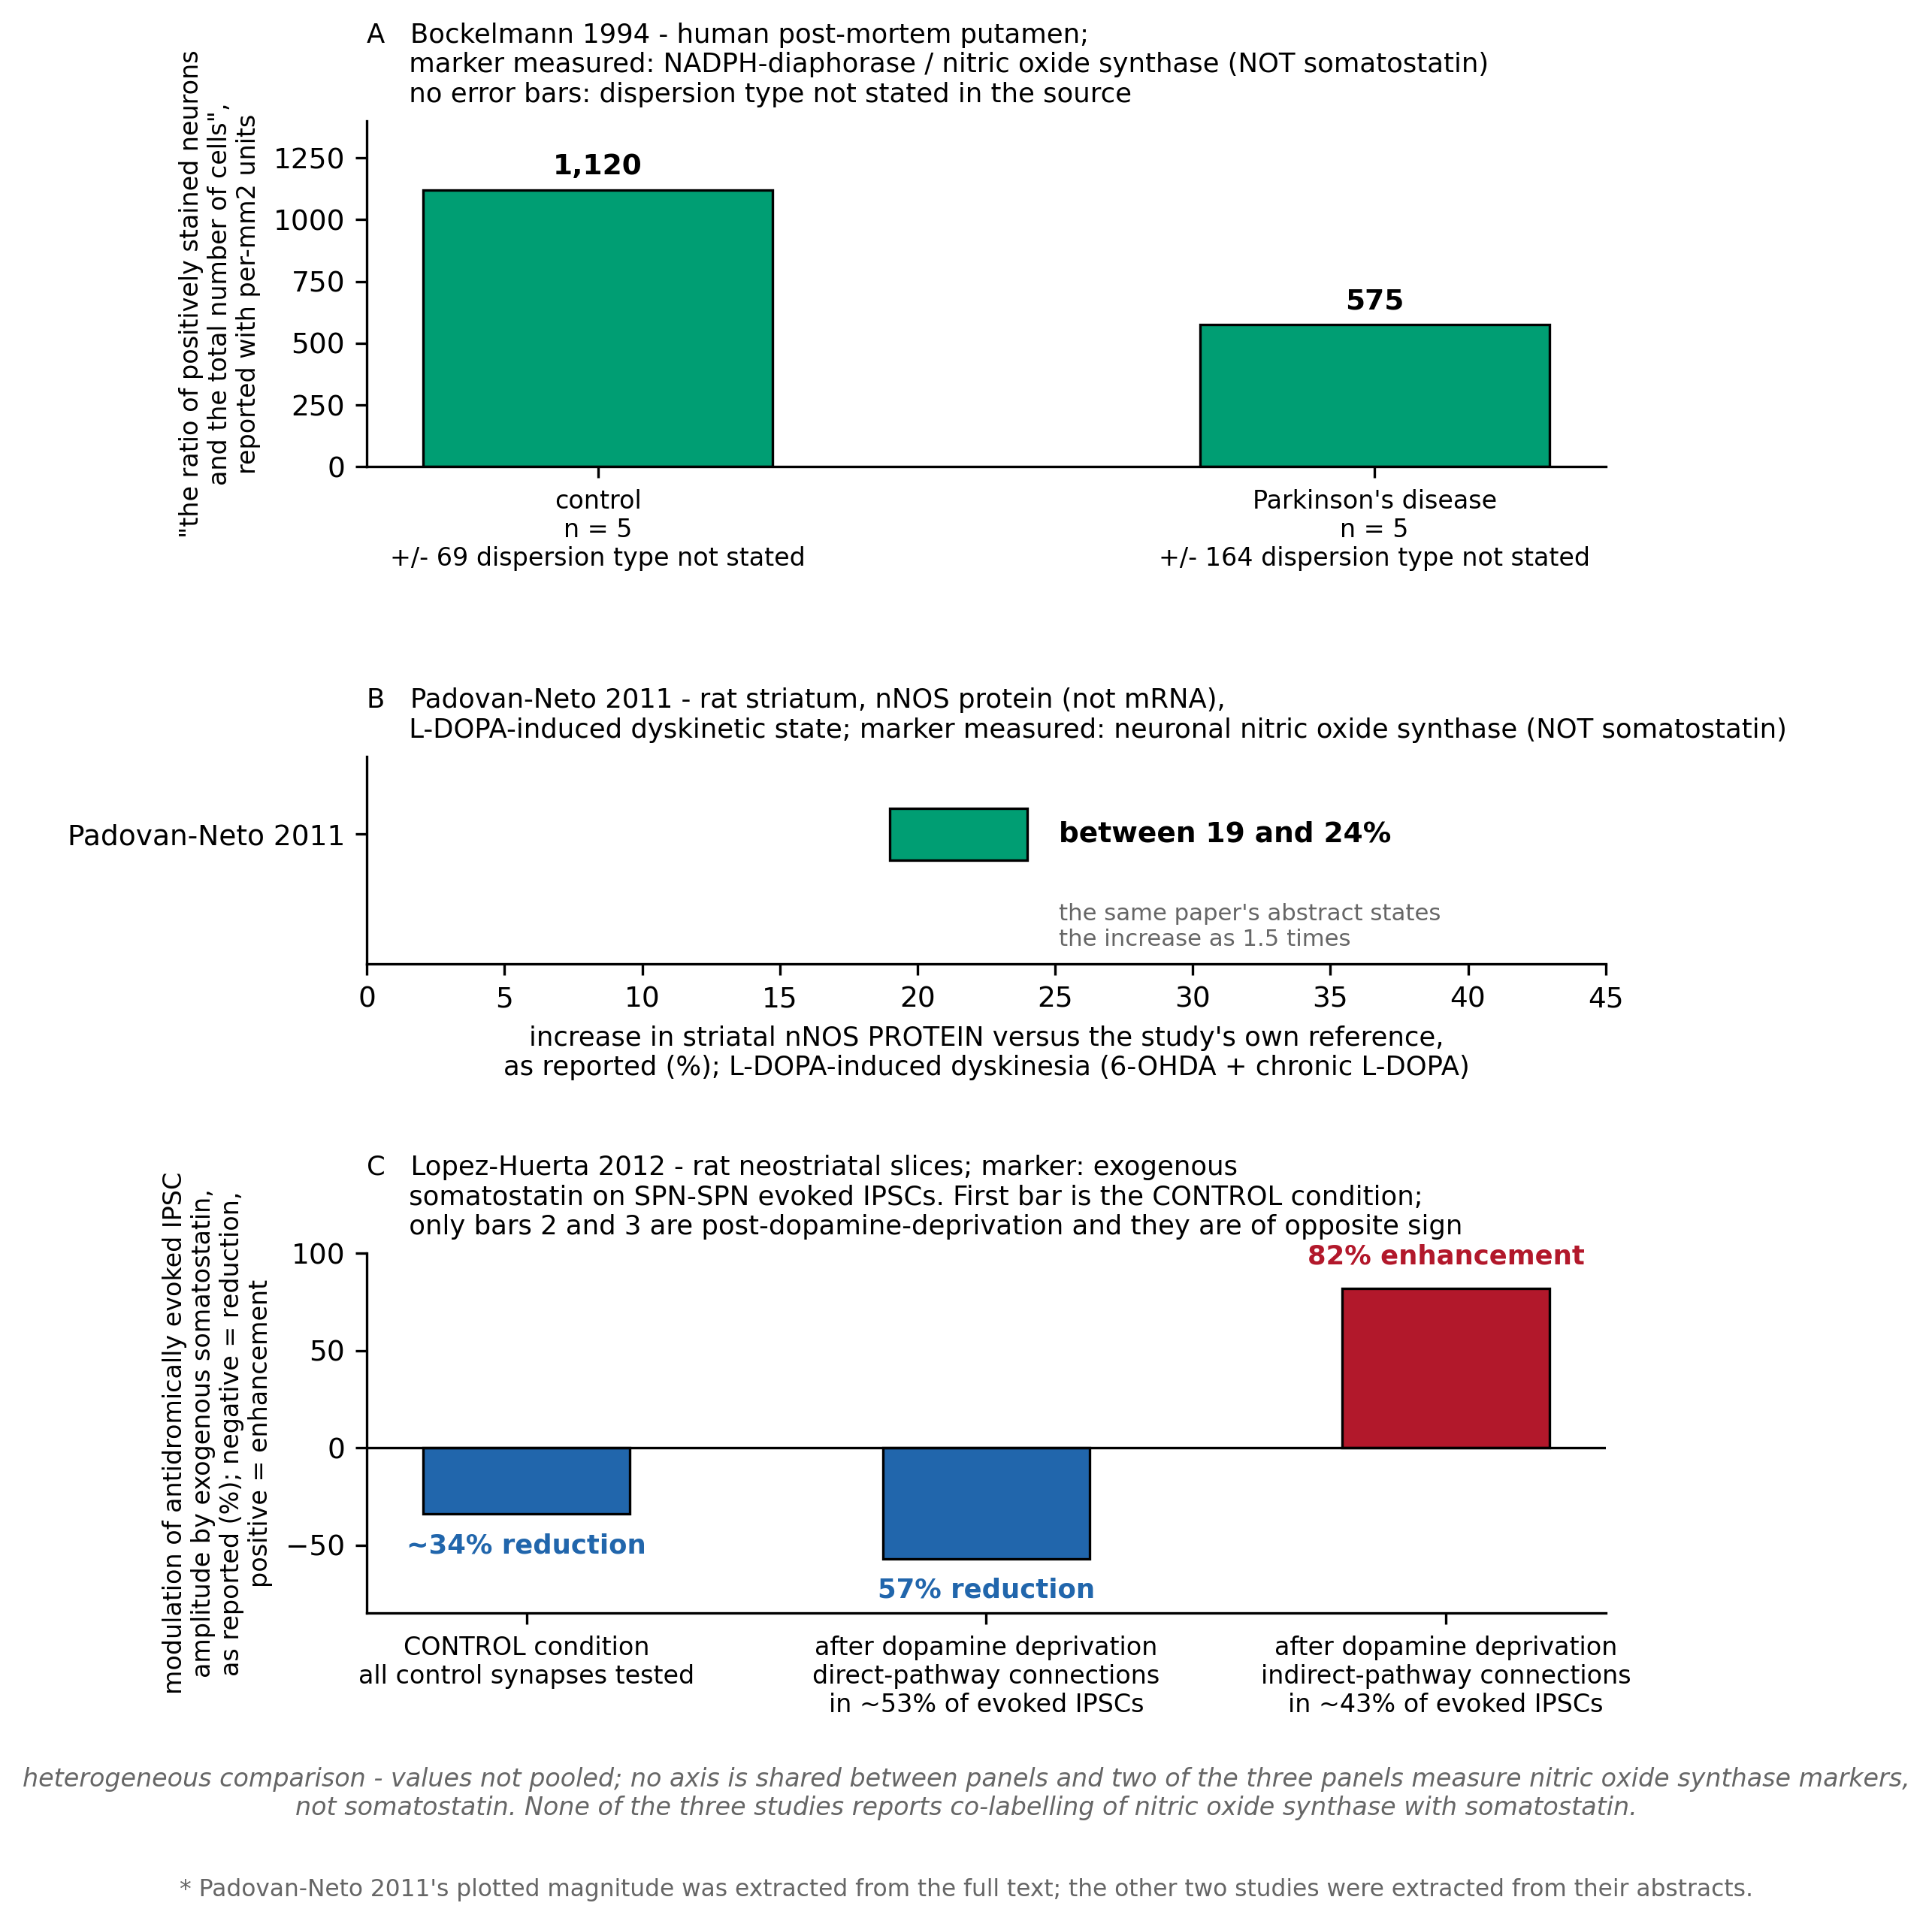

In [ ]:
fig